In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import urllib.request
import zipfile
import os

# Dataset download link
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Download the ZIP file
urllib.request.urlretrieve(url, "sms_dataset.zip")

# Extract the ZIP file
with zipfile.ZipFile("sms_dataset.zip", "r") as zip_file:
    zip_file.extractall("sms_data")

print("Dataset downloaded and extracted successfully!")
print(os.listdir("sms_data"))

Dataset downloaded and extracted successfully!
['readme', 'SMSSpamCollection']


In [3]:
df = pd.read_csv(
    "sms_data/SMSSpamCollection",
    sep="\t",
    names=["label", "message"],
    header=None,
    encoding="utf-8"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Number of messages: 5572

Missing values:
label      0
message    0
dtype: int64

Message categories:
label
ham     4825
spam     747
Name: count, dtype: int64


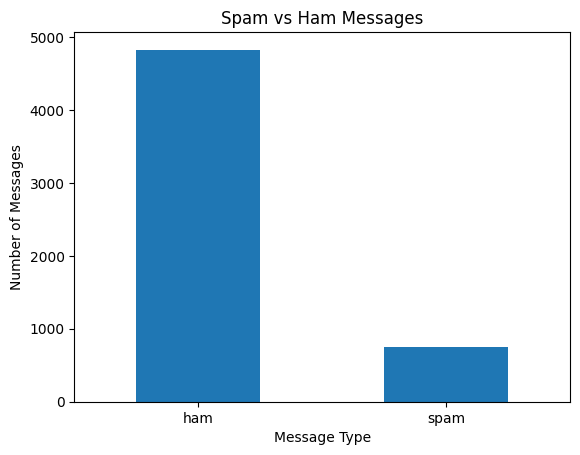

In [4]:
# Check the dataset size
print("Number of messages:", len(df))

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count spam and ham messages
print("\nMessage categories:")
print(df["label"].value_counts())

# Visualize the categories
df["label"].value_counts().plot(
    kind="bar",
    title="Spam vs Ham Messages"
)

plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

In [5]:
# X contains the SMS messages
X = df["message"]

# y contains the correct labels: spam or ham
y = df["label"]

print("Example message:")
print(X.iloc[0])

print("\nCorrect label:")
print(y.iloc[0])

Example message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Correct label:
ham


In [6]:
# Import the TF-IDF tool
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF converter
tfidf = TfidfVectorizer(stop_words="english")

# Convert the SMS messages into numerical features
X_tfidf = tfidf.fit_transform(X)

print("Text converted into numbers!")
print("Shape of numerical data:", X_tfidf.shape)

Text converted into numbers!
Shape of numerical data: (5572, 8444)


In [7]:
from sklearn.model_selection import train_test_split

# Split the original text before applying TF-IDF
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Learn the vocabulary from training messages only
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert test messages using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("Training features:", X_train_tfidf.shape)
print("Testing features:", X_test_tfidf.shape)

Training messages: 4457
Testing messages: 1115
Training features: (4457, 7403)
Testing features: (1115, 7403)


In [8]:
from sklearn.naive_bayes import MultinomialNB

# Create the machine learning model
model = MultinomialNB()

# Train the model using training messages
model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


Model Accuracy: 97.04%

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.78      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



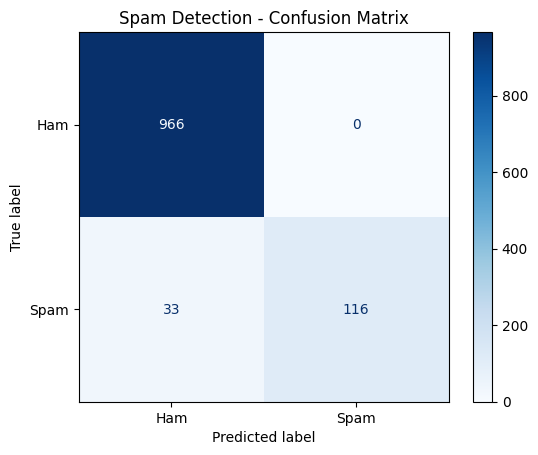

In [9]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict labels for test messages
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Display detailed evaluation metrics
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)

plt.title("Spam Detection - Confusion Matrix")
plt.show()

In [10]:
def predict_message(message):
    # Convert the message into TF-IDF features
    message_tfidf = tfidf.transform([message])

    # Predict spam or ham
    prediction = model.predict(message_tfidf)[0]

    if prediction == "spam":
        print("Prediction: SPAM")
    else:
        print("Prediction: HAM (Legitimate message)")


# Test examples
predict_message("Congratulations! You have won a free prize. Claim now!")
predict_message("Hey, are we meeting at the library today?")

Prediction: SPAM
Prediction: HAM (Legitimate message)


In [11]:
import joblib

joblib.dump(model, "spam_detection_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


In [12]:
from google.colab import files

files.download("spam_detection_model.pkl")
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model Accuracy: 97.04%

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.78      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



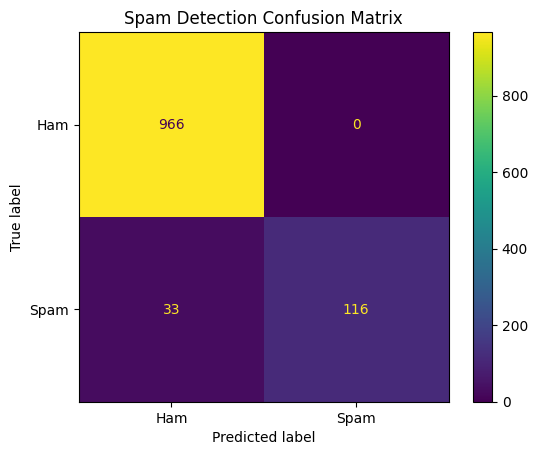

In [13]:

# Make predictions on the test messages
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Display detailed results
from sklearn.metrics import classification_report

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    display_labels=["Ham", "Spam"]
)

plt.title("Spam Detection Confusion Matrix")
plt.show()
